In [27]:
import sys
import pandas as pd
import sklearn
import xgboost as xgb
import numpy as np

print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Numpy:", np.__version__)

Python executable: C:\Users\jeepe\IT8532\.venv\Scripts\python.exe
Pandas: 3.0.5
Scikit-learn: 1.9.0
XGBoost: 3.4.1
Numpy: 2.5.2


In [75]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

print("Project root file breadcrumb:", PROJECT_ROOT)
print("Data directory breadcrumb:", DATA_DIR)

for file in DATA_DIR.glob("*.csv"):
    print(file.name)

Project root file breadcrumb: C:\Users\jeepe\IT8532\SHREDR-AI
Data directory breadcrumb: C:\Users\jeepe\IT8532\SHREDR-AI\data
staDynBenignLab.csv
staDynVt2955Lab.csv
staDynVxHeaven2698Lab.csv


In [7]:
benign = pd.read_csv(DATA_DIR / "staDynBenignLab.csv")
vxheaven = pd.read_csv(DATA_DIR / "staDynVxHeaven2698Lab.csv")
virustotal = pd.read_csv(DATA_DIR / "staDynVt2955Lab.csv")

print("Benign:", benign.shape)
print("VxHeaven:", vxheaven.shape)
print("VirusTotal:", virustotal.shape)

Benign: (595, 1087)
VxHeaven: (2698, 1087)
VirusTotal: (2955, 1088)


In [8]:
print("Benign columns:")
print(benign.columns.tolist())

print("\nVxHeaven columns:")
print(vxheaven.columns.tolist())

print("\nVirusTotal columns:")
print(virustotal.columns.tolist())

Benign columns:
['Unnamed: 0', 'filename', 'Virtual', 'Offset', 'loc', 'Import', 'Imports', 'var', 'Forwarder', 'UINT', 'LONG', 'BOOL', 'WORD', 'BYTES', 'large', 'short', 'dd', 'db', 'dw', 'XREF', 'ptr', 'DATA', 'FUNCTION', 'extrn', 'byte', 'word', 'dword', 'char', 'DWORD', 'stdcall', 'arg', 'locret', 'asc', 'align', 'WinMain', 'unk', 'cookie', 'off', 'nullsub', 'DllEntryPoint', 'System32', 'dll', 'CHUNK', 'BASS', 'HMENU', 'DLL', 'LPWSTR', 'void', 'HRESULT', 'HDC', 'LRESULT', 'HANDLE', 'HWND', 'LPSTR', 'int', 'HLOCAL', 'FARPROC', 'ATOM', 'HMODULE', 'WPARAM', 'HGLOBAL', 'entry', 'rva', 'COLLAPSED', 'config', 'exe', 'Software', 'CurrentVersion', '__imp_', 'INT_PTR', 'UINT_PTR', '---Seperator', 'PCCTL_CONTEXT', '__IMPORT_', 'INTERNET_STATUS_CALLBACK', '.rdata:', '.data:', '.text:', 'case', 'installdir', 'market', 'microsoft', 'policies', 'proc', 'scrollwindow', 'search', 'trap', 'visualc', '___security_cookie', 'assume', 'callvirtualalloc', 'exportedentry', 'hardware', 'hkey_current_user'

In [11]:
display(benign.head())

,Unnamed: 0,filename,Virtual,Offset,loc,Import,Imports,var,Forwarder,UINT,...,count_file_written,count_file_exists,count_file_deleted,count_file_copied,count_file_renamed,count_regkey_written,count_regkey_deleted,count_file_opened,count_dll_loaded,label
0,0,005aea0582da91b95d44f616c7e1257f6b97514445970b...,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,006bcbf75d4dcf4da65f5b89e4ed1a77c2733f1a8d80b9...,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,022fdc3d34c83da8b8905fa04047127f51d0023cdea324...,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,03877b98c8be5f43a6ab6e0e7dad493082897aceb80256...,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,04bc9c75612c5489ad943b31e4bf55827b47c25cd2583d...,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


compare schemas and use only features common to all three files, while keeping source information seperate for analysis

In [76]:

benign_cols = set(benign.columns)
vx_cols = set(vxheaven.columns)
vt_cols = set(virustotal.columns)

common_cols = benign_cols & vx_cols & vt_cols

print("\nOnly in benign:")
print(sorted(benign_cols - vx_cols - vt_cols))

print("\nOnly in VxHeaven:")
print(sorted(vx_cols - benign_cols - vt_cols))

print("\nOnly in VirusTotal:")
print(sorted(vt_cols - benign_cols - vx_cols))

print("Columns common to all three:", len(common_cols))


Only in benign:
['Unnamed: 0']

Only in VxHeaven:
[]

Only in VirusTotal:
[]
Columns common to all three: 1085


In [13]:
print("Benign not in VxHeaven:")
print(sorted(benign_cols - vx_cols))

print("\nVxHeaven not in benign:")
print(sorted(vx_cols - benign_cols))

print("\nVirusTotal not in benign:")
print(sorted(vt_cols - benign_cols))

Benign not in VxHeaven:
['Unnamed: 0', 'filename']

VxHeaven not in benign:
['SafeArrayPtrOfIndex', '__vbaVarIndexLoad']

VirusTotal not in benign:
['SafeArrayPtrOfIndex', '__vbaVarIndexLoad']


In [15]:
common_cols = [
    col for col in benign.columns
    if col in vxheaven.columns and col in virustotal.columns
]

print("Common columns:", len(common_cols))
print(type(common_cols))

Common columns: 1085
<class 'list'>


In [77]:
benign_clean = benign[common_cols].copy()
vx_clean = vxheaven[common_cols].copy()
vt_clean = virustotal[common_cols].copy()

TypeError: Passing a set as an indexer is not supported. Use a list instead.

In [19]:
benign_clean["source"] = "benign_dataset"
vx_clean["source"] = "vxheaven"
vt_clean["source"] = "virustotal"

In [18]:
df = pd.concat(
    [benign_clean, vx_clean, vt_clean],
    ignore_index=True
)

print("Combined shape:", df.shape)
print(df[["label", "source"]].value_counts())

Combined shape: (6248, 1086)
label  source        
1      virustotal        2955
       vxheaven          2698
0      benign_dataset     595
Name: count, dtype: int64


In [20]:
# 1. Confirm combined dataset shape and class/source counts

print("Combined shape:", df.shape)

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nSource counts:")
print(df["source"].value_counts())

print("\nLabel by source:")
print(df.groupby(["source", "label"]).size())

Combined shape: (6248, 1086)

Label counts:
label
1    5653
0     595
Name: count, dtype: int64

Source counts:
source
virustotal        2955
vxheaven          2698
benign_dataset     595
Name: count, dtype: int64

Label by source:
source          label
benign_dataset  0         595
virustotal      1        2955
vxheaven        1        2698
dtype: int64


Define feature matrix and target (exclusing non-features):

In [21]:
# 2. Separate target and features

DROP_COLUMNS = [
    col for col in [
        "label",
        "filename",
        "sha256",
        "Unnamed: 0",
        "source"
    ]
    if col in df.columns
]

y = df["label"].copy()
X = df.drop(columns=DROP_COLUMNS)

print("Dropped columns:", DROP_COLUMNS)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Dropped columns: ['label', 'sha256', 'source']
Feature matrix shape: (6248, 1083)
Target shape: (6248,)


In [22]:
# 3. Inspect feature data types

print(X.dtypes.value_counts())

int64      1069
float64      14
Name: count, dtype: int64


In [23]:
# 4. Find non-numeric features

non_numeric = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of non-numeric columns:", len(non_numeric))
print(non_numeric[:100])

Number of non-numeric columns: 0
[]


In [24]:
# 5. Missing-value audit

missing = X.isna().sum()

print("Columns with missing values:", (missing > 0).sum())

missing_summary = (
    missing[missing > 0]
    .sort_values(ascending=False)
)

display(missing_summary.head(30))

Columns with missing values: 0


Series([], dtype: int64)

In [28]:
# 6. Infinite-value audit

numeric_X = X.select_dtypes(include=["number"])

inf_count = np.isinf(numeric_X).sum().sum()

print("Total infinite values:", inf_count)

Total infinite values: 0


In [29]:
nunique = X.nunique(dropna=False)

constant_cols = nunique[nunique <= 1].index.tolist()

print("Constant columns:", len(constant_cols))
print(constant_cols[:100])

Constant columns: 839
['Virtual', 'Offset', 'Import', 'Imports', 'var', 'Forwarder', 'BYTES', 'large', 'short', 'XREF', 'FUNCTION', 'extrn', 'dword', 'DWORD', 'stdcall', 'locret', 'unk', 'nullsub', 'DllEntryPoint', 'System32', 'CHUNK', 'BASS', 'HMENU', 'DLL', 'LPWSTR', 'void', 'HRESULT', 'HDC', 'LRESULT', 'HWND', 'LPSTR', 'HLOCAL', 'FARPROC', 'ATOM', 'HMODULE', 'WPARAM', 'HGLOBAL', 'rva', 'COLLAPSED', 'config', 'exe', 'Software', 'CurrentVersion', '__imp_', 'INT_PTR', 'UINT_PTR', '---Seperator', 'PCCTL_CONTEXT', '__IMPORT_', 'INTERNET_STATUS_CALLBACK', 'case', 'installdir', 'market', 'microsoft', 'policies', 'scrollwindow', 'search', 'trap', 'visualc', '___security_cookie', 'assume', 'callvirtualalloc', 'exportedentry', 'hardware', 'hkey_current_user', 'hkey_local_machine', 'sp-analysisfailed', 'unableto', 'edx', 'esi', 'ah', 'al', 'ax', 'bh', 'bl', 'bx', 'ch', 'cl', 'cx', 'dh', 'dl', 'dx', 'eax', 'ebp', 'ebx', 'ecx', 'edi', 'esp', 'al.1', 'cdq', 'const', 'cwd', 'dw.1', 'endp', 'ends',

839 of the 1,083 candidate features are constant across the entire combined dataset, so only 244 features vary at all. 

In [30]:
print("Total records:", len(df))
print("Unique SHA256 hashes:", df["sha256"].nunique())

duplicate_rows = df["sha256"].duplicated(keep=False)

print("Rows involved in duplicate hashes:", duplicate_rows.sum())
print(
    "Unique hashes that appear more than once:",
    df.loc[duplicate_rows, "sha256"].nunique()
)

Total records: 6248
Unique SHA256 hashes: 1
Rows involved in duplicate hashes: 6248
Unique hashes that appear more than once: 1


In [31]:
hash_label_counts = df.groupby("sha256")["label"].nunique()

conflicting_hashes = hash_label_counts[hash_label_counts > 1]

print("Hashes with conflicting labels:", len(conflicting_hashes))

Hashes with conflicting labels: 1


In [32]:
print(df["sha256"].value_counts(dropna=False).head())
print("\nExample values:")
print(df["sha256"].head(10).tolist())

sha256
0    6248
Name: count, dtype: int64

Example values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [33]:
ID_COLUMNS = [
    col for col in [
        "label",
        "filename",
        "sha256",
        "Unnamed: 0",
        "source"
    ]
    if col in df.columns
]

feature_df = df.drop(columns=ID_COLUMNS)

print("Features used for duplicate check:", feature_df.shape[1])

Features used for duplicate check: 1083


In [34]:
feature_fingerprint = pd.util.hash_pandas_object(
    feature_df,
    index=False
)

df_check = df.copy()
df_check["feature_fingerprint"] = feature_fingerprint

In [35]:
duplicate_mask = df_check["feature_fingerprint"].duplicated(
    keep=False
)

print("Rows involved in exact duplicate feature vectors:",
      duplicate_mask.sum())

print("Unique duplicated feature vectors:",
      df_check.loc[
          duplicate_mask,
          "feature_fingerprint"
      ].nunique())

Rows involved in exact duplicate feature vectors: 0
Unique duplicated feature vectors: 0


In [36]:
fingerprint_label_counts = (
    df_check
    .groupby("feature_fingerprint")["label"]
    .nunique()
)

conflicting_fingerprints = fingerprint_label_counts[
    fingerprint_label_counts > 1
]

print(
    "Feature vectors appearing with conflicting labels:",
    len(conflicting_fingerprints)
)

Feature vectors appearing with conflicting labels: 0


In [37]:
df_model = (
    df_check
    .drop_duplicates(
        subset="feature_fingerprint",
        keep="first"
    )
    .drop(columns="feature_fingerprint")
    .reset_index(drop=True)
)

print("Original rows:", len(df))
print("Rows after exact duplicate removal:", len(df_model))

Original rows: 6248
Rows after exact duplicate removal: 6248


sha256 is useless in this dataset because every row contains 0
there are no exact duplicate vectors, no conflicting labels for identical feature vectors
all 6,248 rows remain available for modelling.

formal train/validation/test split:

In [38]:
from sklearn.model_selection import train_test_split

DROP_COLUMNS = [
    col for col in [
        "label",
        "filename",
        "sha256",
        "Unnamed: 0",
        "source"
    ]
    if col in df_model.columns
]

X = df_model.drop(columns=DROP_COLUMNS)
y = df_model["label"].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)

print("\nClass counts:")
print(y.value_counts())

print("\nClass percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Feature matrix: (6248, 1083)
Target: (6248,)

Class counts:
label
1    5653
0     595
Name: count, dtype: int64

Class percentages:
label
1    90.48
0     9.52
Name: proportion, dtype: float64


70/15/15 split:

In [39]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (4373, 1083) (4373,)
Validation: (937, 1083) (937,)
Test: (938, 1083) (938,)


In [40]:
def show_distribution(name, y_split):
    print(f"\n{name}")
    print(y_split.value_counts())
    print((y_split.value_counts(normalize=True) * 100).round(2))

show_distribution("Training set", y_train)
show_distribution("Validation set", y_val)
show_distribution("Test set", y_test)


Training set
label
1    3957
0     416
Name: count, dtype: int64
label
1    90.49
0     9.51
Name: proportion, dtype: float64

Validation set
label
1    848
0     89
Name: count, dtype: int64
label
1    90.5
0     9.5
Name: proportion, dtype: float64

Test set
label
1    848
0     90
Name: count, dtype: int64
label
1    90.41
0     9.59
Name: proportion, dtype: float64


In [41]:
train_unique_counts = X_train.nunique(dropna=False)

constant_train_cols = train_unique_counts[
    train_unique_counts <= 1
].index.tolist()

print("Constant training features:", len(constant_train_cols))

Constant training features: 841


In [42]:
X_train = X_train.drop(columns=constant_train_cols)
X_val = X_val.drop(columns=constant_train_cols)
X_test = X_test.drop(columns=constant_train_cols)

print("Training features after removal:", X_train.shape[1])
print("Validation features after removal:", X_val.shape[1])
print("Test features after removal:", X_test.shape[1])

Training features after removal: 242
Validation features after removal: 242
Test features after removal: 242


In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print("Baseline validation results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_val, baseline_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_val, baseline_pred))
print("Precision:", precision_score(y_val, baseline_pred, zero_division=0))
print("Recall:", recall_score(y_val, baseline_pred, zero_division=0))
print("F1:", f1_score(y_val, baseline_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, baseline_pred))

Baseline validation results
---------------------------
Accuracy: 0.9050160085378869
Balanced accuracy: 0.5
Precision: 0.9050160085378869
Recall: 1.0
F1: 0.9501400560224089

Confusion matrix:
[[  0  89]
 [  0 848]]


It detected all 848 malware samples, but misclassified all 89 benign files as malware. Balanced Accuracy = 0.50. 

In [44]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",

    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,

    subsample=0.8,
    colsample_bytree=0.8,

    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")

XGBoost training complete.


In [45]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

val_prob = xgb_model.predict_proba(X_val)[:, 1]

val_pred = (val_prob >= 0.50).astype(int)

print("XGBoost validation results — threshold 0.50")
print("-------------------------------------------")

print("Accuracy:",
      accuracy_score(y_val, val_pred))

print("Balanced accuracy:",
      balanced_accuracy_score(y_val, val_pred))

print("Malware precision:",
      precision_score(y_val, val_pred))

print("Malware recall:",
      recall_score(y_val, val_pred))

print("Malware F1:",
      f1_score(y_val, val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, val_prob))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_pred))

XGBoost validation results — threshold 0.50
-------------------------------------------
Accuracy: 0.9946638207043756
Balanced accuracy: 0.976938467246131
Malware precision: 0.9952996474735605
Malware recall: 0.9988207547169812
Malware F1: 0.9970570924072985
ROC-AUC: 0.9996422514309943

Confusion matrix:
[[ 85   4]
 [  1 847]]


In [46]:
print(
    classification_report(
        y_val,
        val_pred,
        target_names=["Benign", "Malware"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.9884    0.9551    0.9714        89
     Malware     0.9953    0.9988    0.9971       848

    accuracy                         0.9947       937
   macro avg     0.9918    0.9769    0.9842       937
weighted avg     0.9946    0.9947    0.9946       937



Calculating the two error types explicitly.

FN: malware predicted benign
FP: benign predicted malware

In [47]:
tn, fp, fn, tp = confusion_matrix(
    y_val,
    val_pred
).ravel()

print("True negatives  (benign correctly identified):", tn)
print("False positives (benign flagged as malware):", fp)

print("False negatives (malware missed):", fn)
print("True positives  (malware detected):", tp)

True negatives  (benign correctly identified): 85
False positives (benign flagged as malware): 4
False negatives (malware missed): 1
True positives  (malware detected): 847


In [48]:
# recognition rate
benign_recall = tn / (tn + fp)

print("Benign recall / specificity:", benign_recall)

Benign recall / specificity: 0.9550561797752809


In [49]:
# comparison table
comparison = pd.DataFrame({
    "Model": [
        "Majority-class baseline",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_val, baseline_pred),
        accuracy_score(y_val, val_pred)
    ],

    "Balanced Accuracy": [
        balanced_accuracy_score(y_val, baseline_pred),
        balanced_accuracy_score(y_val, val_pred)
    ],

    "Malware Precision": [
        precision_score(
            y_val,
            baseline_pred,
            zero_division=0
        ),
        precision_score(y_val, val_pred)
    ],

    "Malware Recall": [
        recall_score(
            y_val,
            baseline_pred,
            zero_division=0
        ),
        recall_score(y_val, val_pred)
    ],

    "Malware F1": [
        f1_score(
            y_val,
            baseline_pred,
            zero_division=0
        ),
        f1_score(y_val, val_pred)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Malware Precision,Malware Recall,Malware F1
0,Majority-class baseline,0.9050,0.5000,0.9050,1.0000,0.9501
1,XGBoost,0.9947,0.9769,0.9953,0.9988,0.9971


In [50]:
from sklearn.metrics import f1_score

baseline_macro_f1 = f1_score(
    y_val,
    baseline_pred,
    average="macro"
)

xgb_macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro"
)

print("Baseline Macro F1:",
      baseline_macro_f1)

print("XGBoost Macro F1:",
      xgb_macro_f1)

Baseline Macro F1: 0.47507002801120446
XGBoost Macro F1: 0.9842428319179349


threshold selection:

currently using the default 'threshold = 0.50'
but for malware triage, a false negative is more serious than a false positive

In [51]:
threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):
    preds = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        preds
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, preds),
        "Balanced Accuracy": balanced_accuracy_score(y_val, preds),
        "Precision": precision_score(
            y_val,
            preds,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            preds,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            preds,
            zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,0.05,0.9915,0.9551,0.9907,1.0000,0.9953,8,0
1,0.10,0.9925,0.9607,0.9918,1.0000,0.9959,7,0
2,0.15,0.9915,0.9601,0.9918,0.9988,0.9953,7,1
3,0.20,0.9915,0.9601,0.9918,0.9988,0.9953,7,1
4,0.25,0.9925,0.9657,0.9930,0.9988,0.9959,6,1
5,0.30,0.9925,0.9657,0.9930,0.9988,0.9959,6,1
6,0.35,0.9947,0.9769,0.9953,0.9988,0.9971,4,1
7,0.40,0.9947,0.9769,0.9953,0.9988,0.9971,4,1
8,0.45,0.9947,0.9769,0.9953,0.9988,0.9971,4,1
9,0.50,0.9947,0.9769,0.9953,0.9988,0.9971,4,1


"a false negative is assigned ten times the cost of a false positive since missing malicious software presents greater security risk than sending a benign file for additional review"

In [52]:
FALSE_POSITIVE_COST = 1
FALSE_NEGATIVE_COST = 10

threshold_df["Operational Cost"] = (
    threshold_df["False Positives"] * FALSE_POSITIVE_COST
    +
    threshold_df["False Negatives"] * FALSE_NEGATIVE_COST
)

display(
    threshold_df[
        [
            "Threshold",
            "False Positives",
            "False Negatives",
            "Recall",
            "Balanced Accuracy",
            "Operational Cost"
        ]
    ].sort_values("Operational Cost").round(4)
)

,Threshold,False Positives,False Negatives,Recall,Balanced Accuracy,Operational Cost
1,0.10,7,0,1.0000,0.9607,7
0,0.05,8,0,1.0000,0.9551,8
6,0.35,4,1,0.9988,0.9769,14
7,0.40,4,1,0.9988,0.9769,14
11,0.60,4,1,0.9988,0.9769,14
10,0.55,4,1,0.9988,0.9769,14
9,0.50,4,1,0.9988,0.9769,14
8,0.45,4,1,0.9988,0.9769,14
12,0.65,4,1,0.9988,0.9769,14
13,0.70,4,1,0.9988,0.9769,14


In [53]:
best_row = threshold_df.loc[
    threshold_df["Operational Cost"].idxmin()
]

print("Best threshold by prototype operational cost:")
print(best_row)

Best threshold by prototype operational cost:
Threshold            0.100000
Accuracy             0.992529
Balanced Accuracy    0.960674
Precision            0.991813
Recall               1.000000
F1                   0.995890
False Positives      7.000000
False Negatives      0.000000
Operational Cost     7.000000
Name: 1, dtype: float64


In [54]:
fine_thresholds = np.arange(
    0.10,
    0.61,
    0.01
)

fine_results = []

for threshold in fine_thresholds:
    preds = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        preds
    ).ravel()

    cost = (
        fp * FALSE_POSITIVE_COST
        +
        fn * FALSE_NEGATIVE_COST
    )

    fine_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Cost": cost
    })

fine_df = pd.DataFrame(fine_results)

display(
    fine_df.sort_values(
        ["Cost", "Threshold"]
    ).head(15)
)

,Threshold,TN,FP,FN,TP,Cost
0,0.10,82,7,0,848,7
1,0.11,82,7,0,848,7
2,0.12,82,7,0,848,7
24,0.34,85,4,1,847,14
25,0.35,85,4,1,847,14
26,0.36,85,4,1,847,14
27,0.37,85,4,1,847,14
28,0.38,85,4,1,847,14
29,0.39,85,4,1,847,14
30,0.40,85,4,1,847,14


instead of claiming that SHREDR detects future malware at 99.5%, it's safer to state that XGBoost achieved 99.47% validation accuracy on held-out records drawn from the same source dataset. This does not establish equivalent performance on contemporary or independently collected malware

In [55]:
val_sources = df_model.loc[
    y_val.index,
    "source"
]

validation_analysis = pd.DataFrame({
    "actual": y_val,
    "prediction": val_pred,
    "probability": val_prob,
    "source": val_sources
})

for source_name in validation_analysis["source"].unique():
    subset = validation_analysis[
        validation_analysis["source"] == source_name
    ]

    print("\nSOURCE:", source_name)
    print("Samples:", len(subset))

    print(
        confusion_matrix(
            subset["actual"],
            subset["prediction"],
            labels=[0, 1]
        )
    )


SOURCE: vxheaven
Samples: 393
[[  0   0]
 [  0 393]]

SOURCE: virustotal
Samples: 455
[[  0   0]
 [  1 454]]

SOURCE: benign_dataset
Samples: 89
[[85  4]
 [ 0  0]]


The operational threshold was selected using the validation set instead of the final test set. A false negative was assigned ten times the prototype cost of a false positive because failing to identify malicious software is considered more serious than escalating a benign file for further review.
    Under this policy, a threshold of 0.10 produced the lowest validation cost, with zero false negatives and seven false positives.

The benign and malicious records originate from different source collections, so source-specific artefacts may contribute to the model's discrimination. The random held-out validation split therefore measures performance on unseen records from the same source collections rather than on an independently collected malware dataset.

### SHAP.
Attribution part of the rubric (using validation data, not test set)

In [57]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer(X_val)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (937, 242)


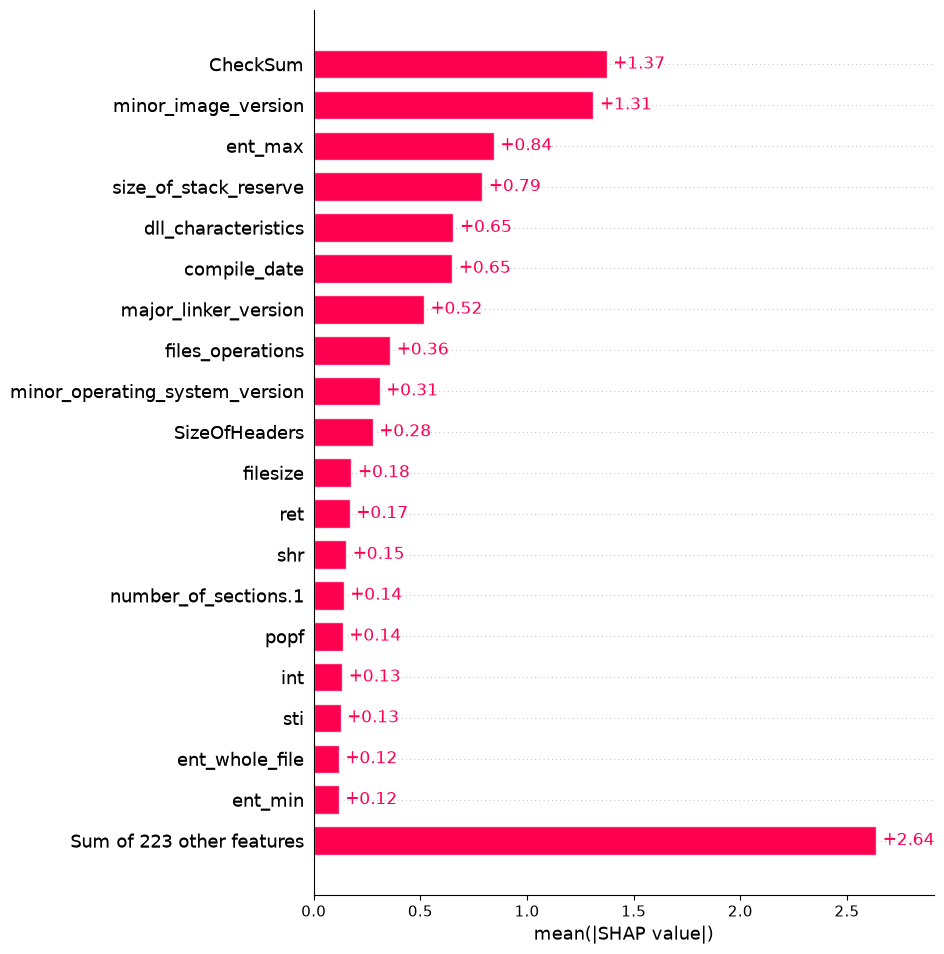

In [59]:
shap.plots.bar(
    shap_values,
    max_display=20
)

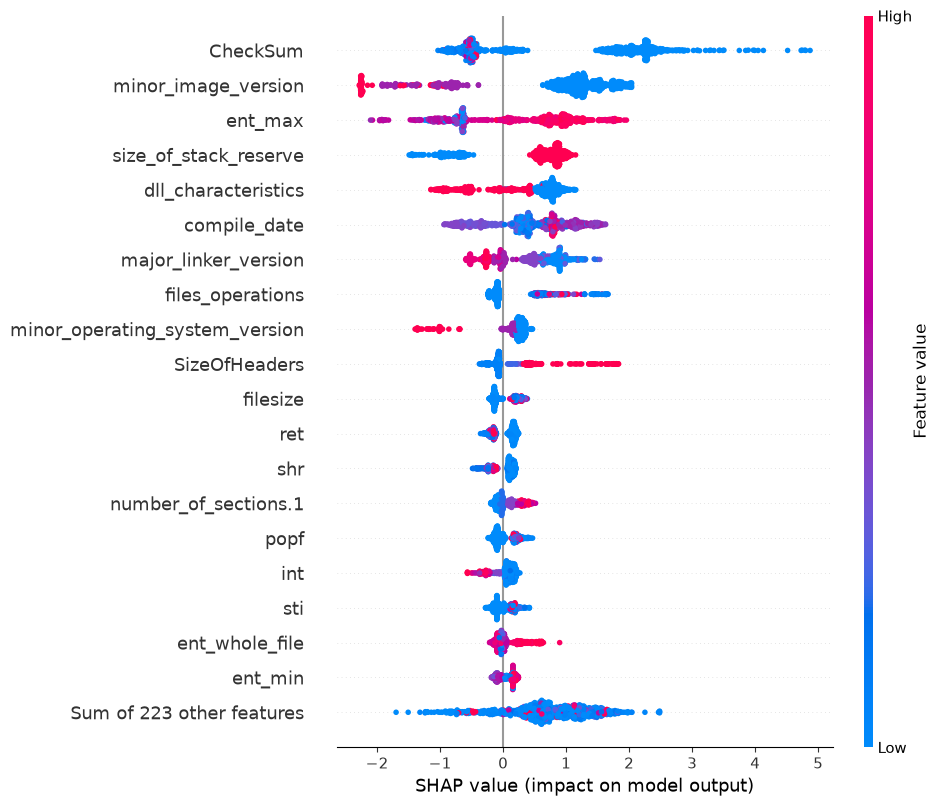

In [60]:
shap.plots.beeswarm(
    shap_values,
    max_display=20
)

In [61]:
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.head(20))

,Feature,Mean Absolute SHAP
221,CheckSum,1.373038
211,minor_image_version,1.311097
186,ent_max,0.844275
222,size_of_stack_reserve,0.790236
216,dll_characteristics,0.654872
196,compile_date,0.649718
202,major_linker_version,0.516400
232,files_operations,0.358595
209,minor_operating_system_version,0.308486
193,SizeOfHeaders,0.276297


strongest contributors are:
- checksum
- minor_image_version
- ent_max
- size_of_stack_reserve
- dll_characteristics
- compile_date
- major_linker_version
- files_operations
- minor_operating_system_version
- SizeOfHeaders

Most are legitimate PE/header or entropy-related characteristics. ent_max, ent_whole_file, filesize, section/header fields, linker/image metadata and DLL characteristics all make sense as things a malware classifier could use.

""
SHAP analysis showed that the model relied mostly on PE-header metadata, entropy-related features, file characteristics and selected instruction/activity features. High-ranking contributors included CheckSum, minor_image_version, ent_max, size_of_stack_reserve, dll_characteristics and compile_date. These attributions describe how features influenced the trained classifier, but they do not establish causal relationships with malicious behaviour. Some metadata features may also reflect source-specific characteristics of the dataset, which limits claims about generalisation to independently collected malware.

subgroup audit.

In [62]:
file_size_q1 = X_train["filesize"].quantile(0.25)
file_size_q3 = X_train["filesize"].quantile(0.75)

print("Training Q1:", file_size_q1)
print("Training Q3:", file_size_q3)

Training Q1: 54458.0
Training Q3: 1567568.0


In [63]:
def filesize_group(value):
    if value <= file_size_q1:
        return "Small"
    elif value >= file_size_q3:
        return "Large"
    else:
        return "Medium"

val_groups = X_val["filesize"].apply(filesize_group)

SELECTED_THRESHOLD = 0.10

val_pred_selected = (
    val_prob >= SELECTED_THRESHOLD
).astype(int)

audit_df = pd.DataFrame({
    "actual": y_val,
    "prediction": val_pred_selected,
    "filesize_group": val_groups
})

In [64]:
group_results = []

for group in ["Small", "Medium", "Large"]:
    subset = audit_df[
        audit_df["filesize_group"] == group
    ]

    tn, fp, fn, tp = confusion_matrix(
        subset["actual"],
        subset["prediction"],
        labels=[0, 1]
    ).ravel()

    group_results.append({
        "Group": group,
        "Samples": len(subset),
        "Accuracy": accuracy_score(
            subset["actual"],
            subset["prediction"]
        ),
        "Balanced Accuracy":
            balanced_accuracy_score(
                subset["actual"],
                subset["prediction"]
            ),
        "FP": fp,
        "FN": fn
    })

group_df = pd.DataFrame(group_results)

display(group_df.round(4))

,Group,Samples,Accuracy,Balanced Accuracy,FP,FN
0,Small,239,1.0000,1.0000,0,0
1,Medium,493,0.9858,0.9507,7,0
2,Large,205,1.0000,1.0000,0,0


"Performance was audited across executable-size groups defined using the first and third quartiles of the training. The model achieved 100% validation accuracy for both small and large files, while the medium-size group achieved 98.58% accuracy and 95.07% balanced accuracy. All seven false positives occured in the medium-size group, while no false negatives appeared in any size group at the selected 0.10 threshold. This shows some variation in false-positive behaviour by file size, although the subgroup sample sizes are limited and the result should not be interpreted as evidence of a causal relationship between file size and model error.

In [65]:
# Final untouched test-set evaluation

SELECTED_THRESHOLD = 0.10

test_prob = xgb_model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= SELECTED_THRESHOLD
).astype(int)

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_pred
)

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

test_auc = roc_auc_score(
    y_test,
    test_prob
)

print("FINAL TEST RESULTS")
print("------------------")
print("Threshold:", SELECTED_THRESHOLD)
print("Accuracy:", test_accuracy)
print("Balanced accuracy:", test_balanced_accuracy)
print("Malware precision:", test_precision)
print("Malware recall:", test_recall)
print("Malware F1:", test_f1)
print("Macro F1:", test_macro_f1)
print("ROC-AUC:", test_auc)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_pred))

FINAL TEST RESULTS
------------------
Threshold: 0.1
Accuracy: 0.9936034115138592
Balanced accuracy: 0.9666666666666667
Malware precision: 0.9929742388758782
Malware recall: 1.0
Malware F1: 0.9964747356051704
Macro F1: 0.9809959884922403
ROC-AUC: 0.999895178197065

Confusion matrix:
[[ 84   6]
 [  0 848]]


In [66]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Benign", "Malware"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     1.0000    0.9333    0.9655        90
     Malware     0.9930    1.0000    0.9965       848

    accuracy                         0.9936       938
   macro avg     0.9965    0.9667    0.9810       938
weighted avg     0.9936    0.9936    0.9935       938



In [67]:
tn_test, fp_test, fn_test, tp_test = confusion_matrix(
    y_test,
    test_pred
).ravel()

print("True negatives:", tn_test)
print("False positives:", fp_test)
print("False negatives:", fn_test)
print("True positives:", tp_test)

test_cost = (
    fp_test * FALSE_POSITIVE_COST
    +
    fn_test * FALSE_NEGATIVE_COST
)

print("Prototype operational cost:", test_cost)

True negatives: 84
False positives: 6
False negatives: 0
True positives: 848
Prototype operational cost: 6


In [68]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

In [69]:
model_path = MODEL_DIR / "shredr_xgboost.json"

xgb_model.save_model(model_path)

print("Saved model:", model_path)

Saved model: C:\Users\jeepe\IT8532\SHREDR-AI\models\shredr_xgboost.json


In [70]:
import json

feature_path = MODEL_DIR / "shredr_features.json"

with open(feature_path, "w") as f:
    json.dump(
        X_train.columns.tolist(),
        f,
        indent=2
    )

print("Saved feature list:", feature_path)

Saved feature list: C:\Users\jeepe\IT8532\SHREDR-AI\models\shredr_features.json


In [71]:
config = {
    "decision_threshold": 0.10,
    "positive_class": 1,
    "positive_class_name": "malware",
    "negative_class": 0,
    "negative_class_name": "benign",
    "false_positive_cost": 1,
    "false_negative_cost": 10,
    "feature_count": len(X_train.columns)
}

config_path = MODEL_DIR / "shredr_model_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("Saved configuration:", config_path)

Saved configuration: C:\Users\jeepe\IT8532\SHREDR-AI\models\shredr_model_config.json


In [72]:
EXAMPLE_DIR = PROJECT_ROOT / "api" / "examples"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)

In [73]:
benign_index = y_test[y_test == 0].index[0]

benign_example = {
    "features": {
        key: float(value)
        for key, value in X_test.loc[benign_index].items()
    }
}

with open(
    EXAMPLE_DIR / "benign_example.json",
    "w"
) as f:
    json.dump(benign_example, f, indent=2)

print("Benign example saved.")

Benign example saved.


In [74]:
malware_index = y_test[y_test == 1].index[0]

malware_example = {
    "features": {
        key: float(value)
        for key, value in X_test.loc[malware_index].items()
    }
}

with open(
    EXAMPLE_DIR / "malware_example.json",
    "w"
) as f:
    json.dump(malware_example, f, indent=2)

print("Malware example saved.")

Malware example saved.
